# Milestone 2 — Exploratory Data Analysis Notebook
**DSAI Labs — Group 10** · Cross-dataset generalisation in building/rooftop segmentation

EDA over the **prepared** dataset (23,372 tiles of 512×512):
- WHU 8,188 · Inria 14,580 · Massachusetts 604

All numbers are computed live from `metadata.csv` (one row per prepared tile).

## 0 · Load metadata

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PREP = Path("/home/bcilab/DSAI/prepared_dataset")
df = pd.read_csv(PREP / "metadata.csv")
df["dataset"] = pd.Categorical(df["dataset"], ["whu","inria","mass"])
df["split"]   = pd.Categorical(df["split"], ["train","validation","test"])
print(len(df), "tiles")
df.head()

23372 tiles


/tmp/ipykernel_2444693/3568956800.py:9: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  df["split"]   = pd.Categorical(df["split"], ["train","validation","test"])


,dataset,split,image,mask,source_id,x_off,y_off,building_pixels,building_share,is_empty
0,whu,train,whu/train/images/whu_0_00.png,whu/train/masks/whu_0_00.png,0,0,0,0,0.000000,True
1,whu,train,whu/train/images/whu_1002_00.png,whu/train/masks/whu_1002_00.png,1002,0,0,4320,0.016479,False
2,whu,train,whu/train/images/whu_1_00.png,whu/train/masks/whu_1_00.png,1,0,0,0,0.000000,True
3,whu,train,whu/train/images/whu_1007_00.png,whu/train/masks/whu_1007_00.png,1007,0,0,75899,0.289532,False
4,whu,train,whu/train/images/whu_101_00.png,whu/train/masks/whu_101_00.png,101,0,0,61837,0.235889,False


## 1 · Tile counts per dataset & split

In [2]:
counts = df.pivot_table(index="dataset", columns="split", values="image",
                        aggfunc="count").fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
counts

split,train,validation,test,total
dataset,,,,
whu,4736,0,2416,7152
inria,10530,2025,2025,14580
mass,548,16,40,604


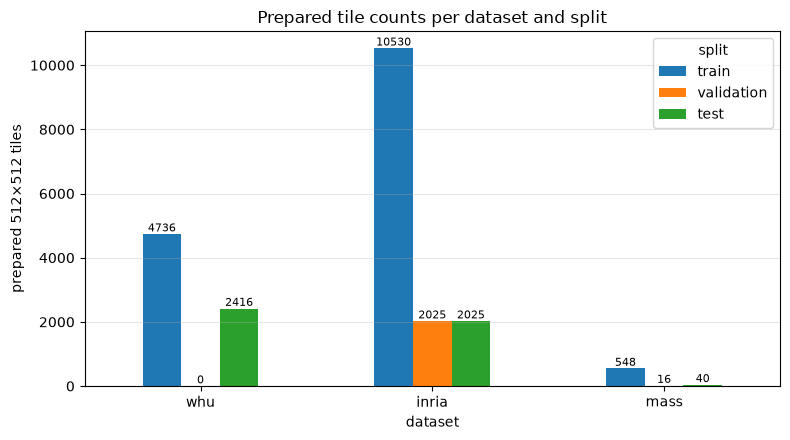

In [3]:
ax = counts.drop(columns="total").plot(kind="bar", figsize=(8,4.5), rot=0)
for c in ax.containers: ax.bar_label(c, fontsize=8)
ax.set_ylabel("prepared 512×512 tiles")
ax.set_title("Prepared tile counts per dataset and split")
ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

## 2 · Class distribution (building share)
Buildings are the minority class in every dataset — this imbalance drives the
choice of loss/metrics later (Dice + focal style losses in Milestone 3).

In [4]:
summary = df.groupby(["dataset","split"]).agg(
    tiles=("image","count"),
    building_px=("building_pixels","sum"),
    mean_share=("building_share","mean"),
).reset_index()
summary["building_%_of_all_px"] = (summary.building_px / (summary.tiles*512*512) * 100).round(2)
summary.drop(columns="building_px")

,dataset,split,tiles,mean_share,building_%_of_all_px
0,whu,train,4736,0.186639,18.66
1,whu,test,2416,0.111280,11.13
2,inria,train,10530,0.163754,16.38
3,inria,validation,2025,0.151491,15.15
4,inria,test,2025,0.137394,13.74
5,mass,train,548,0.132402,13.24
6,mass,validation,16,0.120406,12.04
7,mass,test,40,0.167219,16.72


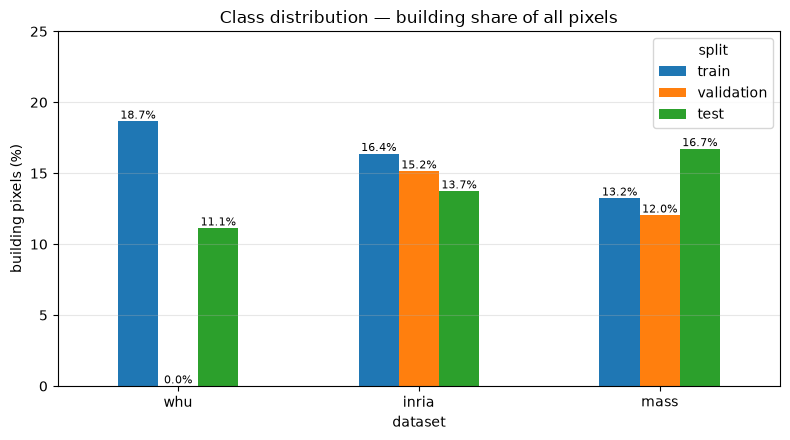

In [5]:
piv = summary.pivot(index="dataset", columns="split", values="building_%_of_all_px")
ax = piv.plot(kind="bar", figsize=(8,4.5), rot=0)
for c in ax.containers: ax.bar_label(c, fmt="%.1f%%", fontsize=8)
ax.set_ylabel("building pixels (%)"); ax.set_ylim(0, 25)
ax.set_title("Class distribution — building share of all pixels")
ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

## 3 · Empty vs fully-built tiles
Tiles with **0 building pixels** contribute nothing to positive learning;
fully-built tiles (>99%) are rare. This motivates sampling strategy.

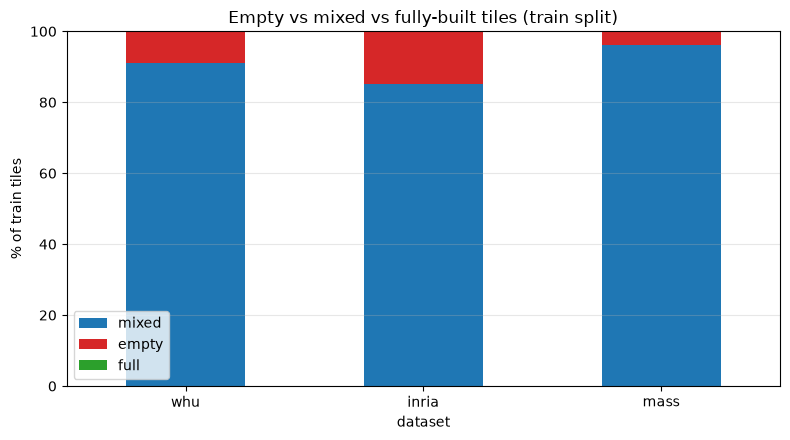

type,mixed,empty,full
dataset,,,
whu,4317,419,0
inria,8952,1578,0
mass,527,21,0


In [6]:
et = df[df.split=="train"].copy()
et["type"] = np.where(et.is_empty, "empty",
             np.where(et.building_share > 0.99, "full", "mixed"))
tab = et.pivot_table(index="dataset", columns="type", values="image",
                     aggfunc="count").fillna(0).astype(int)
tab = tab.reindex(columns=["mixed","empty","full"], fill_value=0).astype(int)
tab_pct = tab.div(tab.sum(axis=1), axis=0)*100

fig, ax = plt.subplots(figsize=(8,4.5))
tab_pct.plot(kind="bar", stacked=True, rot=0,
             color=["#1f77b4","#d62728","#2ca02c"], ax=ax)
ax.set_ylabel("% of train tiles"); ax.set_title("Empty vs mixed vs fully-built tiles (train split)")
for n, i in enumerate(ax.patches): pass
ax.legend(); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()
tab

## 4 · Histogram of building share (10 bins, train split)
Right-skewed in all three datasets: most tiles are building-poor.

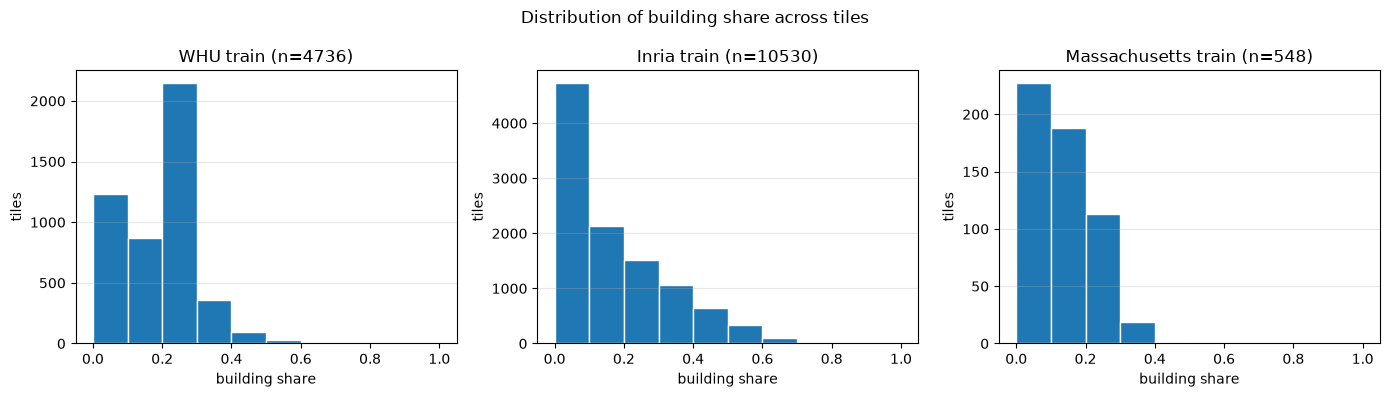

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, d in zip(axes, ["whu","inria","mass"]):
    shares = df[(df.dataset==d) & (df.split=="train")].building_share
    ax.hist(shares, bins=10, range=(0,1), color="#1f77b4", edgecolor="white")
    ax.set_title(f"{ {'whu':'WHU','inria':'Inria','mass':'Massachusetts'}[d] } train (n={len(shares)})")
    ax.set_xlabel("building share"); ax.set_ylabel("tiles"); ax.grid(axis="y", alpha=.3)
plt.suptitle("Distribution of building share across tiles"); plt.tight_layout(); plt.show()

## 5 · Channel statistics (RGB)
Appearance differences between the three datasets are kept intentionally —
no colour correction was applied.

In [8]:
import random
random.seed(42)
rows = []
for d in ["whu","inria","mass"]:
    files = sorted((PREP/d/"train/images").glob("*.png"))
    for f in random.sample(files, min(500, len(files))):
        with Image.open(f) as im: a = np.asarray(im, dtype=np.float32)
        rows.append({"dataset": d, **{f"mean_{c}": v for c, v in zip("RGB", a.reshape(-1,3).mean(0))},
                     **{f"std_{c}": v for c, v in zip("RGB", a.reshape(-1,3).std(0))}})
cs = pd.DataFrame(rows).groupby("dataset").mean().round(2)
cs

,mean_R,mean_G,mean_B,std_R,std_G,std_B
dataset,,,,,,
inria,103.379997,109.120003,100.419998,43.209999,39.779999,37.48
mass,96.290001,97.589996,89.639999,46.020000,44.369999,45.27
whu,110.519997,113.269997,104.889999,51.849998,48.869999,51.00


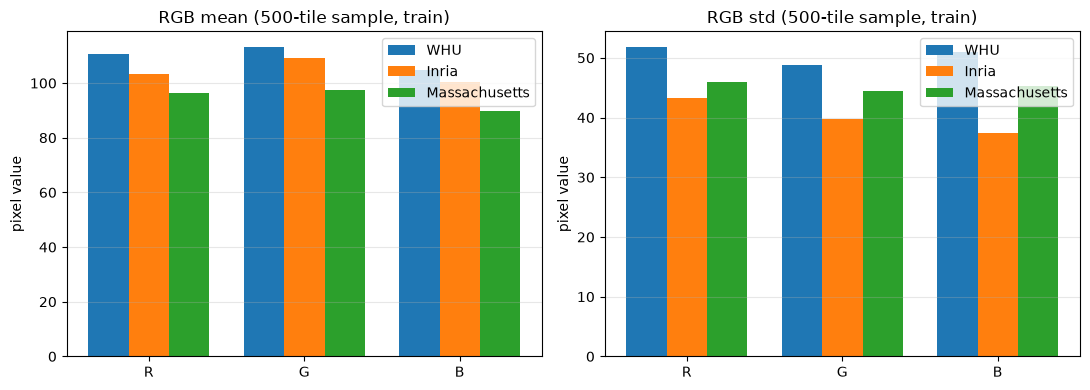

In [9]:
fig, (a1,a2) = plt.subplots(1,2, figsize=(11,4))
x = np.arange(3); w=0.26
for i,d in enumerate(["whu","inria","mass"]):
    lbl = {"whu":"WHU","inria":"Inria","mass":"Massachusetts"}[d]
    a1.bar(x+(i-1)*w, cs.loc[d,[f"mean_{c}" for c in "RGB"]], w, label=lbl)
    a2.bar(x+(i-1)*w, cs.loc[d,[f"std_{c}"  for c in "RGB"]], w, label=lbl)
for ax,t in [(a1,"RGB mean"),(a2,"RGB std")]:
    ax.set_xticks(x); ax.set_xticklabels(["R","G","B"]); ax.set_title(f"{t} (500-tile sample, train)")
    ax.set_ylabel("pixel value"); ax.legend(); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 6 · Visual spot-check — mask overlays
Random tiles with the mask overlaid in red at 50%: do masks sit on the buildings?

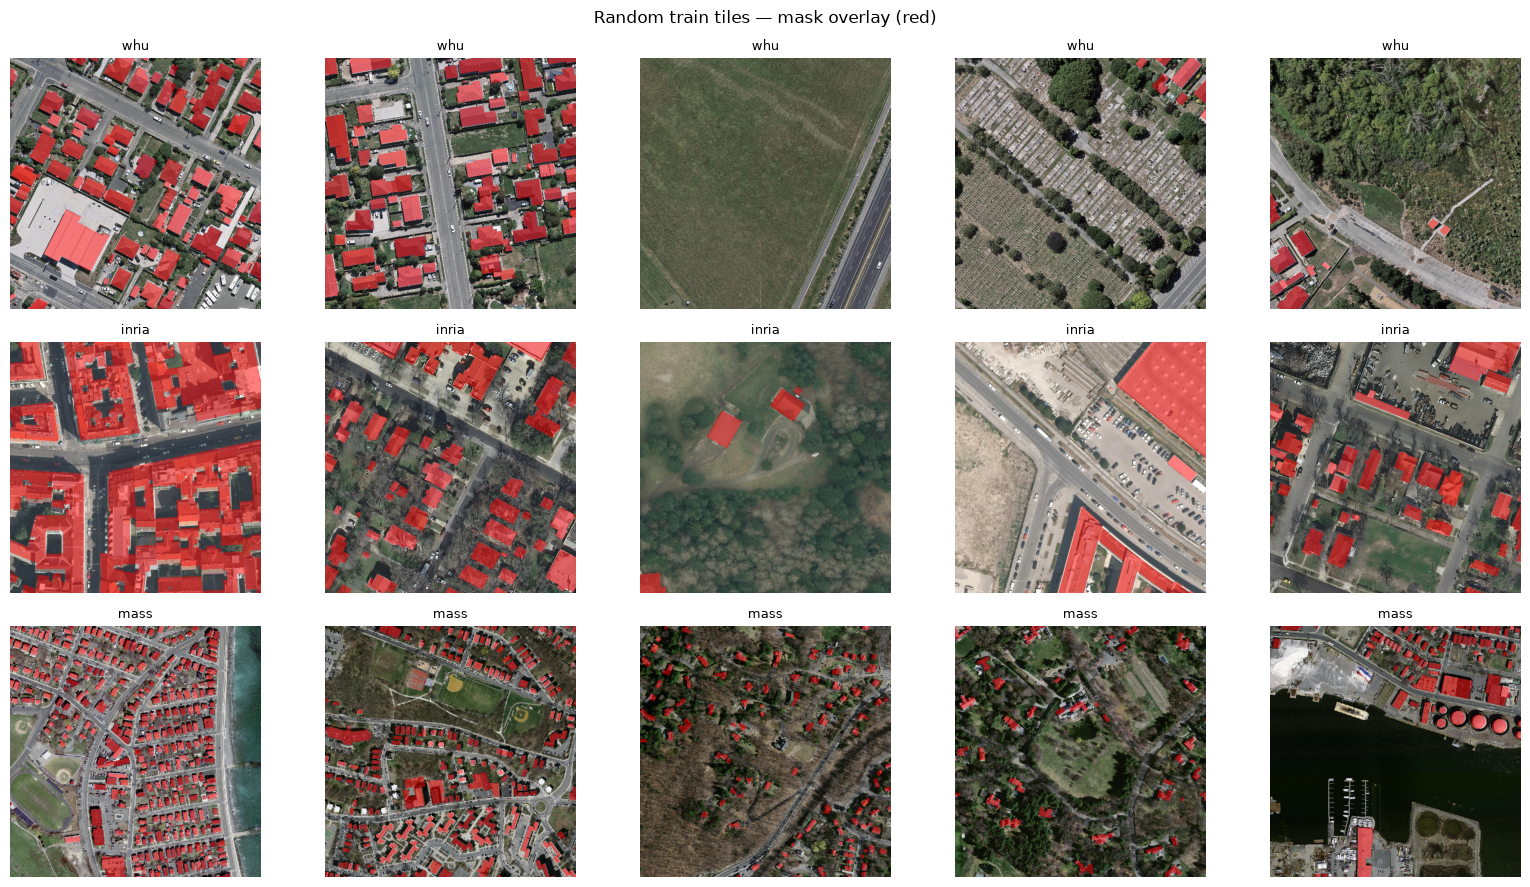

In [10]:
random.seed(7)
fig, axes = plt.subplots(3, 5, figsize=(16, 9))
for r, d in enumerate(["whu","inria","mass"]):
    imgs  = sorted((PREP/d/"train/images").glob("*.png"))
    picks = random.sample(imgs, 5)
    for c, f in enumerate(picks):
        with Image.open(f) as i, Image.open(PREP/d/"train/masks"/f.name) as k:
            ia = np.asarray(i, np.float32); ma = np.asarray(k)
        ov = ia.copy(); mb = ma > 0
        ov[mb] = ov[mb]*0.5 + np.array([255,0,0], np.float32)*0.5
        axes[r,c].imshow(np.clip(ov,0,255).astype(np.uint8)); axes[r,c].axis("off")
        if c==0: axes[r,c].set_ylabel(d, fontsize=12)
        axes[r,c].set_title(f"{d}", fontsize=9)
plt.suptitle("Random train tiles — mask overlay (red)"); plt.tight_layout(); plt.show()

## 7 · Key EDA takeaways
1. **Class imbalance dominates**: buildings cover only 18.7% (WHU), 16.4% (Inria),
   13.2% (Massachusetts) of train pixels.
2. **9–28% of tiles are empty** → metric choice matters (global accuracy is misleading).
3. **Appearance differs strongly** between datasets (see channel stats) — kept unchanged
   on purpose, it is one of the generalisation factors under study.
4. Massachusetts masks contain the dataset's known ~5% annotation noise (speckle
   inside buildings) — documented, not corrected.
5. Prepared dataset is training-ready: 23,372 tiles, common 512×512 PNG format,
   verified pairing, reproducible splits.